# 01 - Data Preparation and Exploratory Data Analysis
**CS316 Project: AI-Based Detection and Forecasting of Seasonal Tourism Imbalance in Saudi Arabia**

**Goal of this notebook**
1. Load the two official tables we use: **D5** (domestic tourists by destination)
   and **I6** (inbound tourists by destination), Ministry of Tourism, Jan 2021 - Dec 2025.
2. Reshape them into one tidy *destination x month* table.
3. Report and handle missing data honestly.
4. Reduce memory usage (rubric: memory optimisation, shown in the report appendix).
5. Explore the data with summary statistics and visualisations.

Course topics: Pandas, importing/summarising/visualising data, missing data.

## 0. Setup (works in Google Colab and on a local computer)

**Google Colab:** run the cell below. It downloads the project from GitHub
(set `REPO_URL` to your repository). If you do not use GitHub, upload the
whole `CS316_Tourism_Project` folder to Google Drive instead and set
`DRIVE_PATH`; the cell will mount Drive and use that folder.

**Locally:** just run the cell; it finds the project folder automatically.

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/Fathimamohh/CS316_Tourism_Project.git"
DRIVE_PATH = "/content/drive/MyDrive/CS316_Tourism_Project"                # <- or edit

if "google.colab" in sys.modules:                      # running inside Colab
    if "<your-username>" not in REPO_URL:              # option A: clone from GitHub
        if not Path("/content/CS316_Tourism_Project").exists():
            subprocess.run(["git", "clone", REPO_URL, "/content/CS316_Tourism_Project"], check=True)
        os.chdir("/content/CS316_Tourism_Project")
    else:                                              # option B: Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir(DRIVE_PATH)
elif Path.cwd().name == "notebooks":                   # local run from notebooks/
    os.chdir("..")

PROJECT = Path.cwd()                                   # project root folder
sys.path.insert(0, str(PROJECT / "src"))               # so we can `import tourism`
FIG = PROJECT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
OUT = PROJECT / "outputs"
print("Project folder:", PROJECT)

Project folder: /home/user/CS316_Tourism_Project


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tourism as t                # project helpers in src/tourism.py

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
DATA_PATH = t.find_dataset()
print(DATA_PATH)

data/DDS_MT_Master_Sheet_2021_2025.xlsx


## 1. What does the raw Excel sheet look like?
The sheets are designed for people, not for computers: several header rows,
merged province cells, one column per destination, two rows per month
(number of tourists, spending) and yearly *Total* rows. We print a few raw
rows of I6 to see this before we reshape it.

In [3]:
# header=None keeps every cell exactly as it is in Excel
raw_i6 = pd.read_excel(DATA_PATH, sheet_name="I6", header=None)
print("Raw I6 shape (rows, columns):", raw_i6.shape)
raw_i6.iloc[5:14, :8]              # header block and the first data rows

Raw I6 shape (rows, columns): (139, 49)


,0,1,2,3,4,5,6,7
5,NaN,NaN,NaN,NaN,منطقة الباحة,NaN,NaN,منطقة القصيم
6,NaN,NaN,NaN,NaN,Albaha province,NaN,NaN,AlQassim Province
7,NaN,NaN,Month,Indicator,الباحة,بلجرشي,أخرى الباحة,بريدة
8,NaN,NaN,NaN,NaN,Al Bahah,BILJURASHI,Other AlBaha,Buraydah
9,NaN,2021,January,Tourists Number (Overnight Visitors),NaN,NaN,53,301
10,NaN,NaN,NaN,Tourists Spending (SAR),NaN,NaN,22551.98,628522.1
11,NaN,NaN,February,Tourists Number (Overnight Visitors),27,NaN,NaN,1148
12,NaN,NaN,NaN,Tourists Spending (SAR),114541.23,NaN,NaN,5003585.02
13,NaN,NaN,March,Tourists Number (Overnight Visitors),31,NaN,NaN,21503


## 2. Reshape into a tidy table
`t.load_tourism()` (see `src/tourism.py`) finds the header rows, forward-fills
only the *labels* (year, month, province), removes yearly totals and melts the
wide table into **one row per (tourist type, destination, month)**.

Important: forward-fill is used only for labels written once in the layout,
never for measured tourist numbers. Blank cells stay missing (`NaN`).

In [4]:
dests, totals = t.load_tourism(DATA_PATH)     # destinations, national TOTAL rows
print("Tidy destination table:", dests.shape)
print("National totals table: ", totals.shape)
dests.head()

Tidy destination table: (4920, 9)
National totals table:  (120, 9)


,date,year,month,tourist_type,province,destination,is_other,tourists,spending_sar
0,2021-01-01,2021,1,Domestic,Aseer,Abha,False,102695.0,1.371810e+08
1,2021-02-01,2021,2,Domestic,Aseer,Abha,False,75475.0,1.213651e+08
2,2021-03-01,2021,3,Domestic,Aseer,Abha,False,95330.0,1.197228e+08
3,2021-04-01,2021,4,Domestic,Aseer,Abha,False,97044.0,1.409182e+08
4,2021-05-01,2021,5,Domestic,Aseer,Abha,False,232860.0,4.212739e+08


**Validation of the parsing:** the sum of all 41 destination columns must equal
the official TOTAL column. A tiny gap (only rounding) proves no value was lost.

In [5]:
gap = t.check_totals(dests, totals)
print(f"Largest relative gap between our sum and the official TOTAL: {gap:.6%}")

Largest relative gap between our sum and the official TOTAL: 0.001185%


## 3. Dataset description
| Column | Meaning | Type |
|---|---|---|
| `date`, `year`, `month` | Reference month (Jan 2021 - Dec 2025) | time |
| `tourist_type` | Domestic (residents, D5) or Inbound (non-residents, I6) | categorical |
| `province` | One of 13 Saudi provinces | categorical |
| `destination` | Main city/governorate **or** "Other <province>" (rest of the province) | categorical |
| `is_other` | True for the "Other ..." categories (not a single city) | boolean |
| `tourists` | Tourists = overnight visitors, by main destination of the trip | numeric (count) |
| `spending_sar` | Tourist spending in Saudi Riyals | numeric (SAR) |

Notes from the workbook's *Metadata* sheet: data come from administrative records
and field surveys; city/governorate figures have a **higher margin of error** than
province figures; 2021 domestic data were revised after the new census.

In [6]:
dests.info()

<class 'pandas.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          4920 non-null   datetime64[us]
 1   year          4920 non-null   int64         
 2   month         4920 non-null   int64         
 3   tourist_type  4920 non-null   str           
 4   province      4920 non-null   str           
 5   destination   4920 non-null   str           
 6   is_other      4920 non-null   bool          
 7   tourists      4376 non-null   float64       
 8   spending_sar  4378 non-null   float64       
dtypes: bool(1), datetime64[us](1), float64(2), int64(2), str(3)
memory usage: 312.4 KB


In [7]:
# How many destinations per province, and how many are "Other" categories?
print(dests.drop_duplicates("destination").groupby("province")["destination"].count()
           .rename("destinations").to_string())
print("\n'Other' categories:", dests.loc[dests.is_other, "destination"].nunique(),
      "of", dests["destination"].nunique())

province
AlQassim            4
Albaha              3
Aseer               3
Eastern             4
Hail                2
Jazan               2
Jouf                3
Madinah             4
Makkah              5
Najran              2
Northern Borders    2
Riyadh              2
Tabuk               5

'Other' categories: 13 of 41


In [8]:
# Summary statistics of the numeric columns, by tourist type
dests.groupby("tourist_type")[["tourists", "spending_sar"]].describe().T.round(0)

tourist_type            Domestic       Inbound
tourists     count  2.456000e+03  1.920000e+03
             mean   1.641170e+05  5.548000e+04
             std    2.344640e+05  2.174680e+05
             min    4.270000e+02  0.000000e+00
             25%    2.691200e+04  4.890000e+02
             50%    7.040400e+04  4.330000e+03
             75%    2.002680e+05  2.318600e+04
             max    3.124927e+06  2.307359e+06
spending_sar count  2.456000e+03  1.922000e+03
             mean   2.305384e+08  3.118611e+08
             std    4.258722e+08  1.696938e+09
             min    2.258970e+05 -0.000000e+00
             25%    2.776651e+07  1.383253e+06
             50%    9.115371e+07  1.250343e+07
             75%    2.376861e+08  7.537450e+07
             max    4.676224e+09  2.709406e+10

## 4. Missing data
We first **measure** missingness, then decide. A blank cell is *not* the same as zero.

In [9]:
# Blank cells (NaN) and reported zeros per tourist type and year.
miss = (dests.assign(missing=dests["tourists"].isna(), zero=dests["tourists"].eq(0))
             .groupby(["tourist_type", "year"])[["missing", "zero"]].sum())
miss["cells"] = dests.groupby(["tourist_type", "year"]).size()
miss

missing  zero  cells
tourist_type year                      
Domestic     2021        0     0    492
             2022        0     0    492
             2023        0     0    492
             2024        4     0    492
             2025        0     0    492
Inbound      2021      154     0    492
             2022      164    12    492
             2023       85    28    492
             2024      137    10    492
             2025        0    83    492

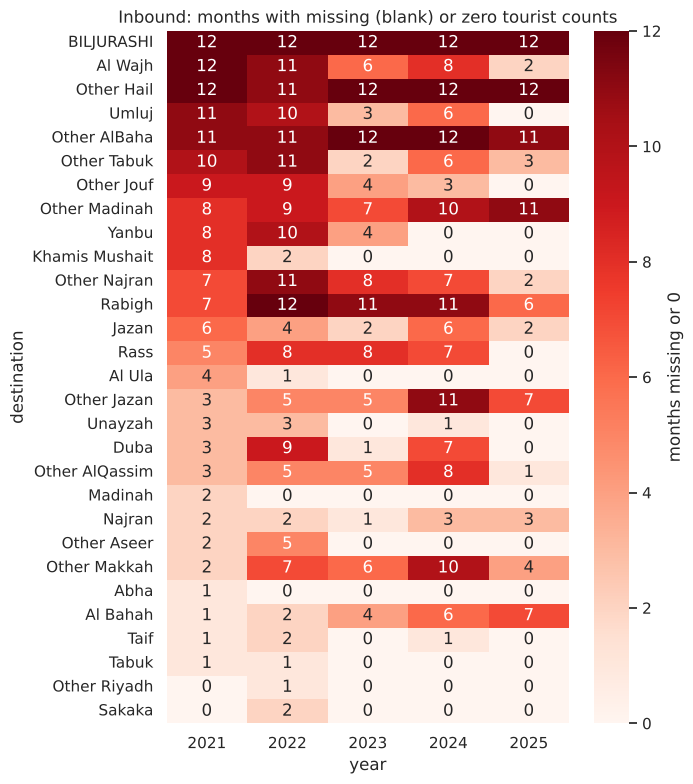

In [10]:
# Months per year with a blank or zero count, inbound destinations with any gaps
heat = (dests[dests.tourist_type == "Inbound"]
        .assign(missing=lambda d: d["tourists"].isna() | d["tourists"].eq(0))
        .pivot_table(index="destination", columns="year", values="missing", aggfunc="sum"))
heat = heat[heat.sum(axis=1) > 0].sort_values(2021, ascending=False)
plt.figure(figsize=(7, 8))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "months missing or 0"})
plt.title("Inbound: months with missing (blank) or zero tourist counts")
plt.tight_layout(); plt.savefig(FIG / "01_missing_inbound.png", dpi=200); plt.show()

**Findings and decisions**
* **Domestic (D5)** is almost complete: only `Other Hail` has 4 blank months (2024).
* **Inbound (I6)** has many blanks for small destinations in 2021-2024 and many
  zeros in 2025. The switch from blanks to zeros in 2025 suggests a change in how
  *not reported / too small to publish* is recorded, so a 0 is not a reliable "no tourists".
* **Decision for analysis (EDA):** keep blanks as `NaN`; sums use only observed values.
* **Decision for forecasting and seasonality modelling:** use only series that are
  observed and positive in all 60 months (`t.eligible_series`). We do **not**
  impute the target, because invented targets would make the evaluation dishonest.
  Forward/backward filling would also copy future information into the past.
* The excluded inbound series are small, so the eligible series still cover
  most tourists (computed below).

In [11]:
# Share of tourists kept when modelling only the fully observed series.
elig = t.eligible_series(dests)
in_elig = dests.set_index(["tourist_type", "destination"]).index.isin(elig)
cover = (dests.assign(eligible=in_elig).groupby(["tourist_type", "eligible"])["tourists"].sum()
              .unstack().pipe(lambda x: x.div(x.sum(axis=1), axis=0) * 100).round(2))
print("Eligible series:", len(elig), "| by type:",
      pd.Series([s[0] for s in elig]).value_counts().to_dict())
print("Share of all tourists (2021-2025) covered by eligible series, %:")
cover

Eligible series: 52 | by type: {'Domestic': 40, 'Inbound': 12}
Share of all tourists (2021-2025) covered by eligible series, %:


eligible,False,True
tourist_type,,
Domestic,0.35,99.65
Inbound,4.77,95.23


## 5. Memory optimisation (for the report appendix)
Text columns are repeated thousands of times. Converting them to `category`
stores each label once plus small integer codes. Integers are downcast and
counts are stored as `float32`. We measure memory with `memory_usage(deep=True)`.

In [12]:
# Deep memory usage (includes string contents) before and after downcasting.
raw_mb = t.memory_mb(raw_i6) + t.memory_mb(pd.read_excel(DATA_PATH, sheet_name="D5", header=None))
opt = t.optimize_memory(dests)
mem = pd.DataFrame({
    "stage": ["Raw sheets I6 + D5 (wide, as read)", "Tidy table (default dtypes)",
              "Tidy table (optimised dtypes)"],
    "memory_MB": [raw_mb, t.memory_mb(dests), t.memory_mb(opt)]})
mem["reduction_vs_tidy_%"] = (1 - mem["memory_MB"] / t.memory_mb(dests)) * 100
mem.loc[0, "reduction_vs_tidy_%"] = np.nan   # raw sheets are a different layout
mem.to_csv(OUT / "memory_optimization.csv", index=False)
print(pd.DataFrame({"before": dests.dtypes.astype(str), "after": opt.dtypes.astype(str)}))
mem.round(3)

                      before           after
date          datetime64[us]  datetime64[us]
year                   int64           int16
month                  int64            int8
tourist_type             str        category
province                 str        category
destination              str        category
is_other                bool            bool
tourists             float64         float32
spending_sar         float64         float64


,stage,memory_MB,reduction_vs_tidy_%
0,"Raw sheets I6 + D5 (wide, as read)",0.480,NaN
1,Tidy table (default dtypes),0.985,0.000
2,Tidy table (optimised dtypes),0.130,86.819


In [13]:
# Downcasting must not change the data. Some counts are survey estimates with
# decimals (e.g. 963.87), so compare with a relative tolerance instead of equality.
a = opt["tourists"].astype(float).to_numpy(); b = dests["tourists"].to_numpy(dtype=float)
assert np.allclose(a, b, rtol=1e-6, equal_nan=True)
ok = b > 0
print("Max relative change:", np.nanmax(np.abs(a[ok] - b[ok]) / b[ok]))
dests = opt                     # continue with the smaller table

Max relative change: 5.6746097131953286e-08


## 6. Exploratory data analysis
### 6.1 National monthly tourists: domestic vs inbound

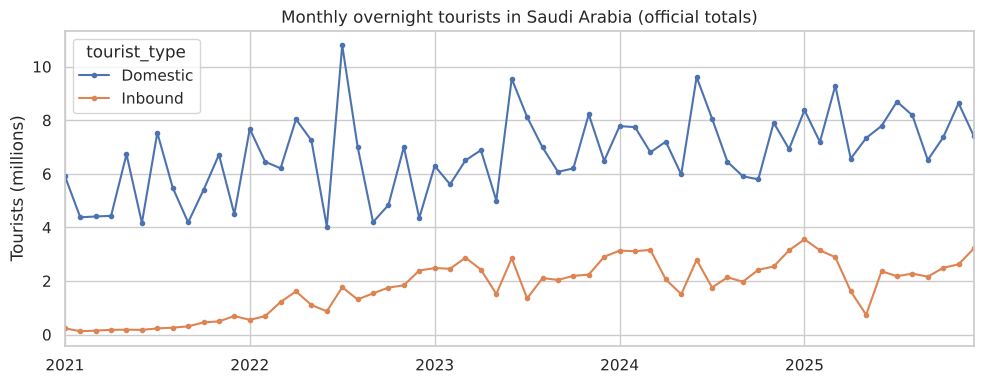

tourist_type,Domestic,Inbound,Inbound share %
year,,,
2021,63.83,3.48,5.17
2022,77.84,16.64,17.61
2023,81.92,27.42,25.08
2024,86.16,29.73,25.65
2025,93.32,29.25,23.87


In [14]:
nat = totals.pivot(index="date", columns="tourist_type", values="tourists") / 1e6
ax = nat.plot(figsize=(10, 4), marker="o", ms=3)
ax.set_ylabel("Tourists (millions)"); ax.set_xlabel("")
ax.set_title("Monthly overnight tourists in Saudi Arabia (official totals)")
plt.tight_layout(); plt.savefig(FIG / "01_national_monthly.png", dpi=200); plt.show()

# Yearly totals in millions and the inbound share of all tourists.
yearly = totals.pivot_table(index="year", columns="tourist_type", values="tourists", aggfunc="sum") / 1e6
yearly["Inbound share %"] = yearly["Inbound"] / (yearly["Domestic"] + yearly["Inbound"]) * 100
yearly.round(2)

### 6.2 Spending per tourist

Spending per tourist (SAR) per month:
                 mean  median     std     min      max
tourist_type                                         
Domestic      1404.0  1377.0   184.0  1036.0   1879.0
Inbound       5341.0  5053.0  1658.0  3296.0  11621.0


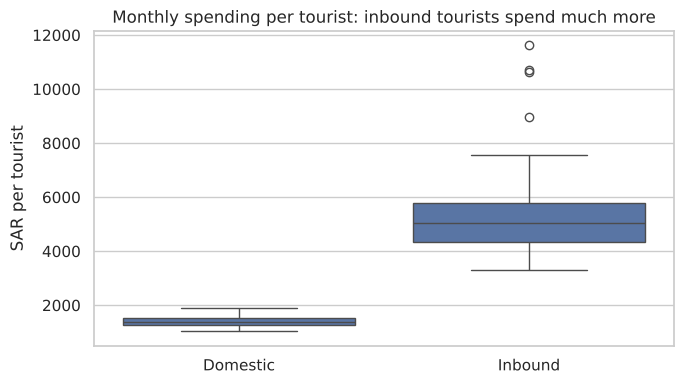

In [15]:
# National spending per tourist for each month.
sp = totals.assign(spend_per_tourist=totals["spending_sar"] / totals["tourists"])
summary = sp.groupby("tourist_type")["spend_per_tourist"].agg(["mean", "median", "std", "min", "max"])
print("Spending per tourist (SAR) per month:\n", summary.round(0))
plt.figure(figsize=(7, 4))
sns.boxplot(data=sp, x="tourist_type", y="spend_per_tourist")
plt.ylabel("SAR per tourist"); plt.xlabel("")
plt.title("Monthly spending per tourist: inbound tourists spend much more")
plt.tight_layout(); plt.savefig(FIG / "01_spend_per_tourist.png", dpi=200); plt.show()

### 6.3 Which destinations receive the most tourists?

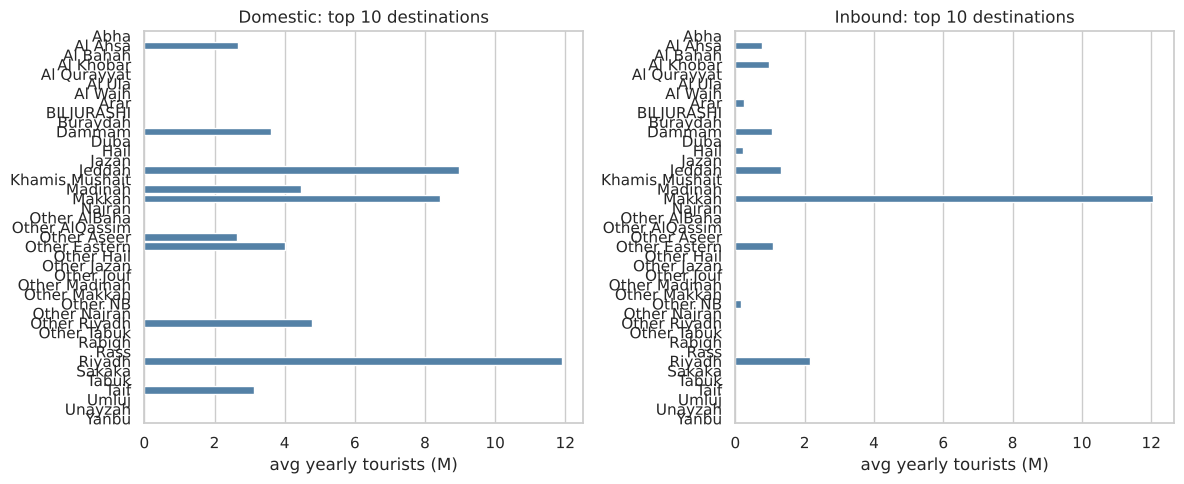

In [16]:
# Sum over the 5 years / 5e6 = average tourists per year, in millions.
top = (dests.groupby(["tourist_type", "destination"], observed=True)["tourists"].sum()
            .div(5e6).rename("avg yearly tourists (M)").reset_index())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (typ, grp) in zip(axes, top.groupby("tourist_type")):
    g = grp.nlargest(10, "avg yearly tourists (M)")
    sns.barplot(data=g, y="destination", x="avg yearly tourists (M)", ax=ax, color="steelblue")
    ax.set_title(f"{typ}: top 10 destinations"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "01_top_destinations.png", dpi=200); plt.show()

In [17]:
# Concentration across destinations: share of the top 3 destinations in each type
for typ, grp in top.groupby("tourist_type"):
    share = grp.nlargest(3, "avg yearly tourists (M)")["avg yearly tourists (M)"].sum() / grp["avg yearly tourists (M)"].sum()
    print(f"{typ}: top-3 destinations receive {share:.1%} of all tourists")

Domestic: top-3 destinations receive 36.4% of all tourists
Inbound: top-3 destinations receive 72.9% of all tourists


### 6.4 Month x year heatmaps (seasonal pattern at a glance)

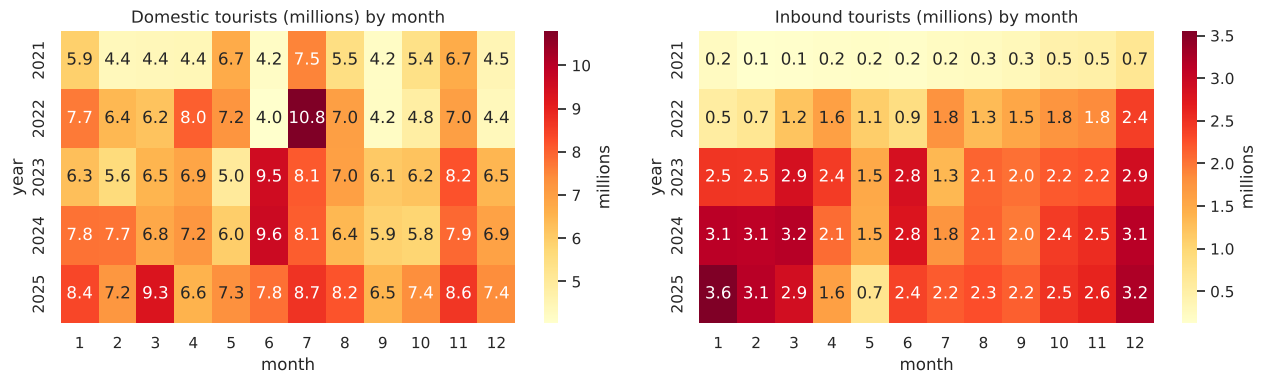

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, typ in zip(axes, ["Domestic", "Inbound"]):
    h = totals[totals.tourist_type == typ].pivot(index="year", columns="month", values="tourists") / 1e6
    sns.heatmap(h, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax, cbar_kws={"label": "millions"})
    ax.set_title(f"{typ} tourists (millions) by month")
plt.tight_layout(); plt.savefig(FIG / "01_heatmap_month_year.png", dpi=200); plt.show()

### 6.5 Distribution of destination-month counts
Counts are strongly right-skewed (a few huge destinations), so we also look at
the log scale. This motivates modelling `log(1 + tourists)` in notebook 03.

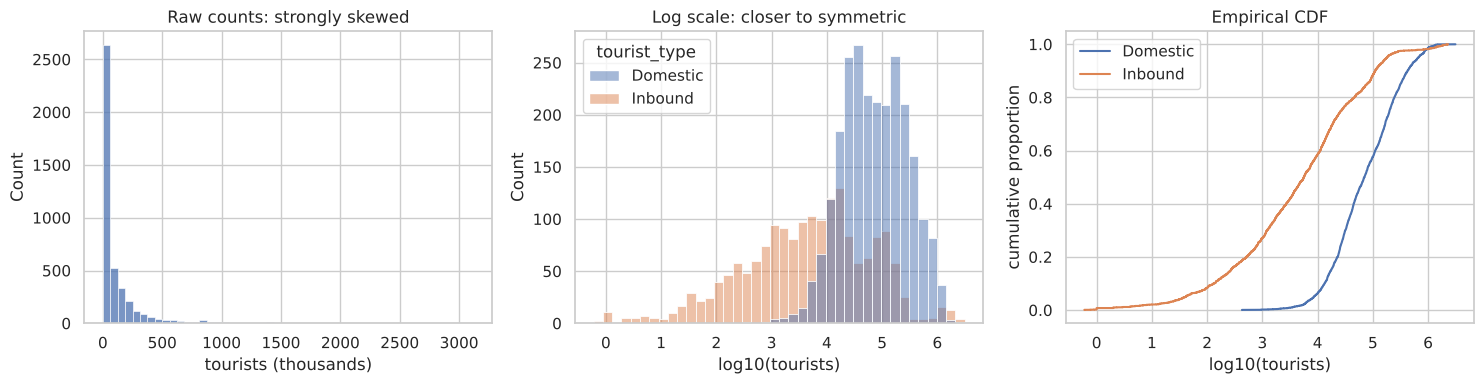

                 0.25     0.50      0.75
tourist_type                            
Domestic      26912.0  70404.0  200268.0
Inbound         840.0   5658.0   26829.0


In [19]:
# Observed, positive counts only (log10 is undefined for 0).
obs = dests.dropna(subset=["tourists"])
obs = obs[obs["tourists"] > 0]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(obs["tourists"] / 1e3, bins=50, ax=axes[0]); axes[0].set_xlabel("tourists (thousands)")
axes[0].set_title("Raw counts: strongly skewed")
sns.histplot(data=obs, x=np.log10(obs["tourists"]), hue="tourist_type", bins=40, ax=axes[1])
axes[1].set_xlabel("log10(tourists)"); axes[1].set_title("Log scale: closer to symmetric")
# Empirical CDF: cumulative proportions 1/n, 2/n, ..., 1 of the sorted values
for typ, g in obs.groupby("tourist_type"):
    x = np.sort(np.log10(g["tourists"].to_numpy(dtype=float)))
    axes[2].step(x, np.arange(1, len(x) + 1) / len(x), label=typ)
axes[2].set_xlabel("log10(tourists)"); axes[2].set_ylabel("cumulative proportion")
axes[2].set_title("Empirical CDF"); axes[2].legend()
plt.tight_layout(); plt.savefig(FIG / "01_distributions.png", dpi=200); plt.show()
print(obs.groupby("tourist_type")["tourists"].quantile([0.25, 0.5, 0.75]).unstack().round(0))

### 6.6 Relationship between tourists and spending

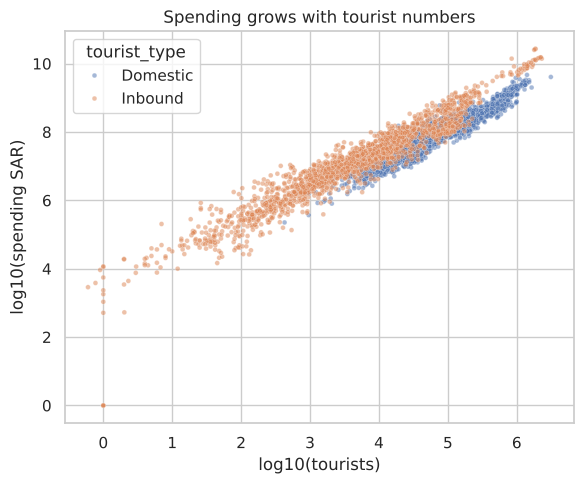

Pearson correlation tourists vs spending: {'Domestic': 0.921, 'Inbound': 0.927} 
(correlation shows association, not causation)


In [20]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=obs, x=np.log10(obs["tourists"]), y=np.log10(obs["spending_sar"].clip(lower=1)),  # clip avoids log10(0)
                hue="tourist_type", s=12, alpha=0.5)
plt.xlabel("log10(tourists)"); plt.ylabel("log10(spending SAR)")
plt.title("Spending grows with tourist numbers")
plt.tight_layout(); plt.savefig(FIG / "01_tourists_vs_spending.png", dpi=200); plt.show()
corr = obs.groupby("tourist_type")[["tourists", "spending_sar"]].corr().xs("tourists", level=1)["spending_sar"]
print("Pearson correlation tourists vs spending:", corr.round(3).to_dict(),
      "\n(correlation shows association, not causation)")

## 7. Save the analysis-ready dataset
The other notebooks reload the data with the same `t.load_tourism()` function,
so this CSV is mainly for sharing and inspection (e.g. in Excel).

In [21]:
(PROJECT / "data" / "processed").mkdir(exist_ok=True)
dests.to_csv(PROJECT / "data" / "processed" / "tourism_destination_month.csv", index=False)
totals.to_csv(PROJECT / "data" / "processed" / "tourism_national_totals.csv", index=False)
print("Saved processed CSV files.")

Saved processed CSV files.


## 8. Summary of EDA findings
* Parsing is verified: destination sums equal the official TOTAL (max gap 0.001%).
* Domestic tourists grew from 63.8 M (2021) to 93.3 M (2025). Inbound grew from 3.5 M (2021, COVID) to
  about 29-30 M in 2024-2025, about a quarter of all tourists.
* An inbound tourist spends about 5,341 SAR per month on average vs. 1,404 SAR for a domestic tourist.
* Inbound tourism is highly concentrated in space: the top-3 destinations (Makkah, Riyadh, Jeddah)
  receive 72.9% of inbound tourists vs. 36.4% for domestic.
* Counts are right-skewed. On the log scale they are close to symmetric, so we model `log(1 + tourists)`.
* Missing data affect mainly small inbound destinations. The 52 fully observed series cover 99.65% of
  domestic and 95.2% of inbound tourists.
* Memory: the optimised dtypes reduce the tidy table by about 87% (see `outputs/memory_optimization.csv`).